# NR PRACH channel extraction on XCZU67DR
Upload a repeated 139-element short-preamble useful symbol at 15.36 MS/s. One active CC and one RACH channel perform frequency translation and 4× decimation. Verify the 37-sample relative arrival time with a known-root cyclic matched filter. The receiver checks an independent clock window and every sample timestamp. A separate capture contains noise alone.

In [1]:
import os, sys
from pathlib import Path
examples = Path(os.environ.get("PRACH_EXAMPLES", "../packages/pynq-dfe/examples/prach")).resolve()
sys.path.insert(0, str(examples))
from board import run
from model import LIMITS, CASES, correlation, unpack, predicted
import numpy as np
import matplotlib.pyplot as plt
print("Predeclared limits", LIMITS)

Matplotlib is building the font cache; this may take a moment.


Predeclared limits {'count': 1024, 'clocks': 64, 'dc_hz': 3750, 'tone_coherence': 0.98, 'shift_error': 1, 'detection': 0.75, 'noise_max': 0.35, 'psl_error_db': 5.0}


In [2]:
out = Path(os.environ.get("PRACH_OUTPUT", "."))
result = run(Path(os.environ["PRACH_BITFILE"]).resolve(), out)
print("Software/hardware versions", result["versions"], "events", result["events"])
for row in result["rows"]:
    print(f"{row['test']:38s}  measured {row['measured']}  predicted {row['predicted']}  {'PASS' if row['passed'] else 'FAIL'}")

Software/hardware versions ((1, 8, 0, 0), (2, 0, 6, 0)) events {'DecimatorOverflow': 0, 'MixerOverflow': 0, 'DecimatorOverrun': 0, 'SelectorOverrun': 0, 'RachUpdate': 0, 'CCSequenceError': [0, 0, 0], 'FrameInitTrigger': [1, 0, 0], 'FrameError': [0, 0, 0]}
tone count                              measured 1024  predicted 1024  PASS
tone clocks/sample                      measured [64, 64]  predicted 64  PASS
tone RCID/antenna                       measured 0  predicted 0  PASS
reference count                         measured 1024  predicted 1024  PASS
reference clocks/sample                 measured [64, 64]  predicted 64  PASS
reference RCID/antenna                  measured 0  predicted 0  PASS
shifted count                           measured 1024  predicted 1024  PASS
shifted clocks/sample                   measured [64, 64]  predicted 64  PASS
shifted RCID/antenna                    measured 0  predicted 0  PASS
noise count                             measured 1024  predicted 1024  P

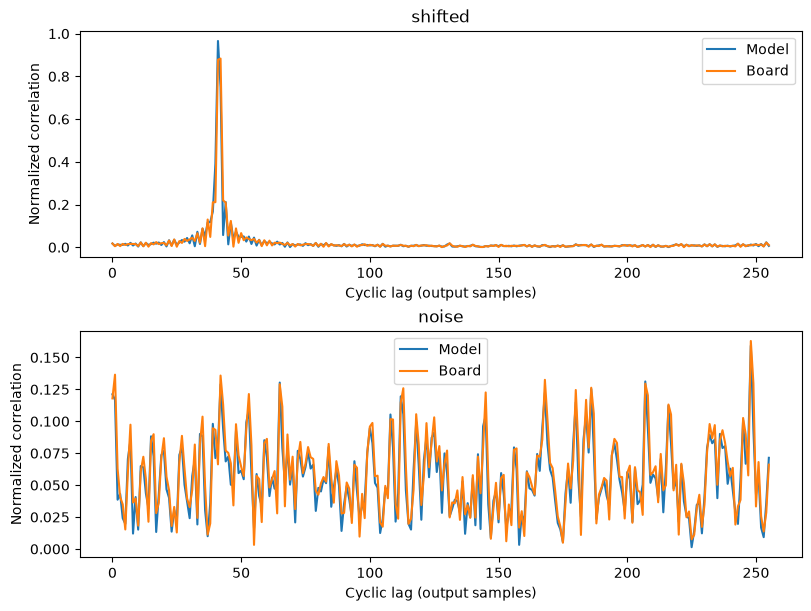

In [3]:
fig, axes = plt.subplots(2, 1, constrained_layout=True, figsize=(8, 6))
for ax, case in zip(axes, ("shifted", "noise")):
    y = unpack(np.load(out / (case + "-capture.npy")))
    p = predicted(np.load(out / (case + "-input.npy")))
    for samples, label in [(p, "Model"), (y, "Board")]:
        ax.plot(correlation(samples)[3], label=label)
    ax.set(xlabel="Cyclic lag (output samples)", ylabel="Normalized correlation", title=case)
    ax.legend()
fig.savefig(out / "correlation.png")
plt.show()
assert all(row["passed"] for row in result["rows"])